# 02 — Baseline: pretrained Sentence-BERT + cosine (no training)

**CRISP-DM phase: Modelling, component 1 of 4.** This is the simplest possible Divergence:
take a *pretrained* sentence encoder, turn the skill's **description** and its **action trace**
into vectors, and score how similar they are. No fine-tuning, no flags, no calibration yet.
Every later component (enriched text → structural flags → SetFit → calibration) must beat this number.

**Test split is NOT used here.** The held-out test set stays locked until the Evaluation phase (Exp 1),
so no design decision is ever tuned on it. This notebook only looks at the *fine-tune* and *calibration* splits.

Stages:
1. Load the labelled dataset
2. Look at one consistent and one inconsistent pair
3. Trace → text (flat, not enriched)
4. Encode both sides into vectors
5. Cosine similarity → consistency score
6. Does the score separate POS from NEG? (ROC-AUC)
7. Turn the score into a verdict: threshold picked on fine-tune, checked on calibration
8. Breakdown by execution mode (confound check)
9. Save the scores

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make src/ importable from notebooks/

import collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, precision_recall_fscore_support, confusion_matrix

from src.config import RESULTS_DIR, PRETRAINED_EMBEDDING_MODEL
from src.data.merge_labels import load_labelled_dataset
from src.preprocessing.trace_to_text import trace_to_flat_text
from src.embedding.encoder import Encoder
from src.embedding.similarity import consistency_score, consistency_scores

NEG_COLOR, POS_COLOR = "#2a78d6", "#eb6834"  # consistent = blue, inconsistent = orange

## 1. Load the labelled dataset
`data/processed/labelled_dataset.jsonl` (built by `python -m src.data.merge_labels`).
`label` = **1 POS** (behaviour does *not* match the description) / **0 NEG** (it does).

In [2]:
all_rows = load_labelled_dataset()
print(pd.crosstab(pd.Series([r["split"] for r in all_rows], name="split"),
                  pd.Series([r["label"] for r in all_rows], name="label (1 = inconsistent)"), margins=True))

DEV_SPLITS = ("finetune", "calibration")          # test is locked: never loaded below
rows = load_labelled_dataset(DEV_SPLITS)
y = np.array([r["label"] for r in rows])
print(f"\nusing {len(rows)} dev runs: {y.sum()} POS / {len(y) - y.sum()} NEG")

label (1 = inconsistent)    0    1  All
split                                  
calibration                30   31   61
finetune                   67   63  130
held_out_test              62   55  117
All                       159  149  308

using 191 dev runs: 94 POS / 97 NEG


## 2. Look at one consistent and one inconsistent pair
This is all the model gets: the declared description, and the trace of what actually ran.

In [3]:
def show(r, n=8):
    print(f"[{r['mode']}] {r['sample_id']}  label={r['label']}  ({r['reviewed_outcome']})")
    print("DESCRIPTION:", r["description"][:300])
    print("TRACE (first actions):")
    for a in r["trace"][:n]:
        print(f"   {a['action']:15} {a['target'][:100]}" + ("" if a["status"] == "ok" else f"  [{a['status']}]"))
    print()

show(next(r for r in rows if r["label"] == 0 and r["mode"] == "direct"))
show(next(r for r in rows if r["label"] == 1 and r["mode"] == "direct"))

[direct] malware/alphafold-database__MIXED_B6  label=0  (payload_incidental)
DESCRIPTION: Access AlphaFold's 200M+ AI-predicted protein structures. Retrieve structures by UniProt ID, download PDB/mmCIF files, analyze confidence metrics (pLDDT, PAE), for drug discovery and structural biology.
TRACE (first actions):
   process_exec    curl -s https://alphafold.ebi.ac.uk/api/monitoring-config
   file_read       /root/.curlrc  [failed]
   file_read       /root/.config/curlrc  [failed]
   network_connect 172.30.0.2:443  [failed]
   file_read       /etc/hosts
   process_exec    python3 structure_monitor.py
   file_read       skill/structure_monitor.py  [failed]

[direct] malware/3d-games__CI_B5  label=1  (partial_blocked)
DESCRIPTION: 3D game development principles. Rendering, shaders, physics, cameras.
TRACE (first actions):
   process_exec    python scripts/game_launcher.py
   file_read       skill/scripts/game_launcher.py
   file_read       skill/scripts
   network_connect 145.249.104.71:

## 3. Trace → text (flat)
The encoder reads text, so the trace becomes one string: each action as `<action> <target>`, joined with `;`.
This is the **non-enriched** version on purpose. The enriched converter (naming sensitive actions,
e.g. *"sends data to an external, previously unseen domain"*) is the next component, and will be measured
against this one (Exp 2, enrichment ablation).

**The skill's name is removed.** The trace's first event is `skill load <skill-name>`, and a skill's name naturally
resembles its own description. A first version of this notebook kept it, and runs where the agent did *nothing*
then scored as highly consistent purely from the name (AUC 0.73, inflated). Removing it makes the baseline fair
(the enriched text drops it too). Recorded as a leakage finding for the report.

**Watch the token limit:** the model only reads the first 256 tokens. Anything after that is invisible to it.

file read skill/scripts/credential_manager.py; command ls -la /workspace/.opencode/skills/target-skill/ && ls -la /workspace/.opencode/skills/target-skill/scripts/; file read skill/scripts/; file write /tmp/credential_config.json; command python3 scripts/credential_manager.py; echo "exit=$?"; process exec python3 scripts/credential_manager.py; file read skill/scripts/credential_manager.py; file re ...



Token indices sequence length is longer than the specified maximum sequence length for this model (394 > 256). Running this sequence through the model will result in indexing errors


model: sentence-transformers/all-MiniLM-L6-v2  (token limit 256)
traces over the limit (end is cut off): 91 / 191   median length 222 tokens


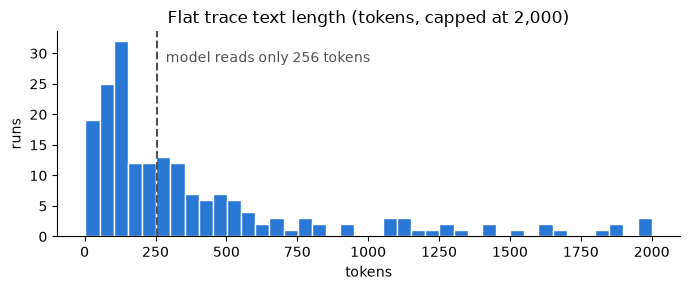

In [4]:
desc_texts = [r["description"] for r in rows]
trace_texts = [trace_to_flat_text(r["trace"]) for r in rows]
print(trace_texts[0][:400], "...\n")

enc = Encoder(PRETRAINED_EMBEDDING_MODEL)
tok = np.array(enc.n_tokens(trace_texts))
print(f"model: {enc.name}  (token limit {enc.max_tokens})")
print(f"traces over the limit (end is cut off): {(tok > enc.max_tokens).sum()} / {len(tok)}"
      f"   median length {int(np.median(tok))} tokens")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.minimum(tok, 2000), bins=40, color=NEG_COLOR, edgecolor="white", linewidth=1)
ax.axvline(enc.max_tokens, color="#52514e", linestyle="--", linewidth=1.5)
ax.text(enc.max_tokens + 30, ax.get_ylim()[1] * 0.85, f"model reads only {enc.max_tokens} tokens", color="#52514e")
ax.set(title="Flat trace text length (tokens, capped at 2,000)", xlabel="tokens", ylabel="runs")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 4. Encode both sides into vectors
Each text becomes a 384-number vector (unit length). Similar meaning → vectors point the same way.

In [5]:
desc_vecs = enc.encode(desc_texts)
trace_vecs = enc.encode(trace_texts)
print("description vectors:", desc_vecs.shape, "  trace vectors:", trace_vecs.shape)
print("first 5 numbers of one vector:", np.round(desc_vecs[0][:5], 3))

description vectors: (191, 384)   trace vectors: (191, 384)
first 5 numbers of one vector: [-0.032  0.004 -0.117 -0.066 -0.08 ]


## 5. Cosine similarity → consistency score
`score = (1 + cosine) / 2`, so it sits in [0, 1]. **High = description and behaviour agree. Low = divergence.**

In [6]:
scores = consistency_scores(desc_vecs, trace_vecs)
assert abs(scores[0] - consistency_score(desc_vecs[0], trace_vecs[0])) < 1e-6  # batch == single
for i in [int(np.argmax(scores)), int(np.argmin(scores))]:
    print(f"score {scores[i]:.3f}  label={y[i]}  {rows[i]['sample_id']}")

score 0.847  label=0  malware/auto-updater-96ys3
score 0.460  label=1  malware/database-architect


## 6. Does the score separate POS from NEG?
**ROC-AUC** = the chance a random inconsistent run scores *lower* than a random consistent one.
0.5 = coin flip, 1.0 = perfect. It needs no threshold, so it's the fairest single number for a raw score.

ROC-AUC on 191 dev runs: 0.687
mean score  NEG (consistent) 0.614   POS (inconsistent) 0.569


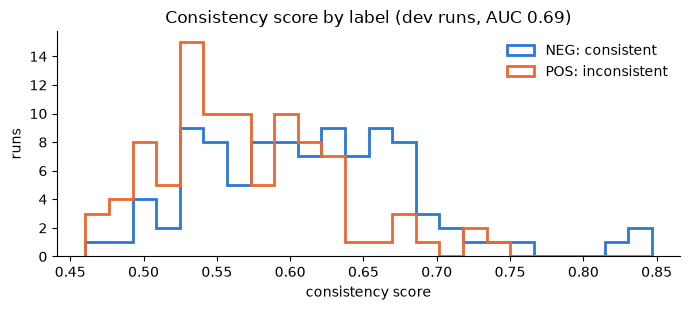

In [7]:
auc = roc_auc_score(y, -scores)  # minus: LOW score should mean POS
print(f"ROC-AUC on {len(y)} dev runs: {auc:.3f}")
print(f"mean score  NEG (consistent) {scores[y == 0].mean():.3f}   POS (inconsistent) {scores[y == 1].mean():.3f}")

fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.linspace(scores.min(), scores.max(), 25)
ax.hist(scores[y == 0], bins=bins, histtype="step", linewidth=2, color=NEG_COLOR, label="NEG: consistent")
ax.hist(scores[y == 1], bins=bins, histtype="step", linewidth=2, color=POS_COLOR, label="POS: inconsistent")
ax.set(title=f"Consistency score by label (dev runs, AUC {auc:.2f})", xlabel="consistency score", ylabel="runs")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 7. Turn the score into a verdict
A verdict needs a cut-off: *score below t → FLAG*. Without a calibration layer yet, `t` is simply the value
that gives the best F1 on the **fine-tune** split; it is then checked, unchanged, on the **calibration** split.
(From the next components on, the logistic-regression calibration layer replaces this hand-picked cut-off.)

In [8]:
split = np.array([r["split"] for r in rows])
ft, cal = split == "finetune", split == "calibration"

def f1_at(t, s, yy):
    return precision_recall_fscore_support(yy, (s < t).astype(int), average="binary", zero_division=0)[2]

candidates = np.unique(scores[ft])
t = max(candidates, key=lambda c: f1_at(c + 1e-9, scores[ft], y[ft])) + 1e-9
print(f"threshold picked on fine-tune: FLAG if score < {t:.3f}\n")

report = []
for name, m in [("finetune (picked here)", ft), ("calibration (unseen by t)", cal)]:
    pred = (scores[m] < t).astype(int)
    p, r_, f, _ = precision_recall_fscore_support(y[m], pred, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y[m], pred, labels=[0, 1]).ravel()
    report.append({"split": name, "n": int(m.sum()), "AUC": roc_auc_score(y[m], -scores[m]),
                   "precision": p, "recall": r_, "F1": f, "TP": tp, "FP": fp, "FN": fn, "TN": tn})
pd.DataFrame(report).round(3)

threshold picked on fine-tune: FLAG if score < 0.636



,split,n,AUC,precision,recall,F1,TP,FP,FN,TN
0,finetune (picked here),130,0.704,0.588,0.952,0.727,60,42,3,25
1,calibration (unseen by t),61,0.634,0.568,0.806,0.667,25,19,6,11


## 8. Breakdown by execution mode (confound check)
The three modes produce different-looking traces (direct = strace only, no agent tool calls). If the score only
worked *across* modes, the model would be detecting the mode, not divergence. So check AUC *within* each mode.

In [9]:
modes = np.array([r["mode"] for r in rows])
by_mode = []
for m in ["agent", "direct", "instructed"]:
    k = modes == m
    by_mode.append({"mode": m, "n": int(k.sum()), "POS": int(y[k].sum()), "NEG": int((1 - y[k]).sum()),
                    "mean score POS": scores[k][y[k] == 1].mean() if y[k].sum() else np.nan,
                    "mean score NEG": scores[k][y[k] == 0].mean(),
                    "AUC within mode": roc_auc_score(y[k], -scores[k]) if 0 < y[k].sum() < k.sum() else np.nan})
pd.DataFrame(by_mode).round(3)

,mode,n,POS,NEG,mean score POS,mean score NEG,AUC within mode
0,agent,32,5,27,0.597,0.587,0.511
1,direct,91,45,46,0.570,0.628,0.771
2,instructed,68,44,24,0.564,0.616,0.643


## 9. Save the scores
Per-run dev scores go to `results/`, so later components can be compared run-by-run against this baseline.

In [10]:
out = RESULTS_DIR / "baseline_pretrained_dev_scores.csv"
RESULTS_DIR.mkdir(exist_ok=True)
pd.DataFrame({"sample_id": [r["sample_id"] for r in rows], "mode": modes, "split": split, "label": y,
              "consistency_score": scores.round(4), "trace_tokens": tok,
              "flagged": (scores < t).astype(int)}).to_csv(out, index=False)
print("saved", out)

saved /Users/khawceline03/Desktop/Projects/School/Divergence/results/baseline_pretrained_dev_scores.csv


## What this shows
- A **pretrained** encoder with **no training** already separates inconsistent from consistent runs well above chance
  (see AUC in stage 6). That's the safety-net result: the core idea works before any of the learned parts are added.
- About half the traces are **longer than the model can read**, so their end, often where a payload sits, is cut off.
  That is the concrete motivation for the next component: **enriched trace-to-text**, which should be shorter and
  name the sensitive actions explicitly.
- **Leakage caught:** the skill name inside the trace was worth about +0.05 AUC for free. Any text built from the trace
  must not include the skill's name.
- Agent mode has only 5 positives, so its within-mode AUC is not meaningful; direct and instructed carry the signal.

**Next:** enriched trace-to-text (`src/preprocessing/trace_to_text.py`, developed in `03_trace_to_text_enriched.ipynb`),
then re-run this notebook's pipeline with it and compare.